# Multidata Causal Discovery for Tropical Cyclone Intensity Forecasting (CausalSHIPS) — solved

**Authors**: Saranya Ganesh S. and Tom Beucler, with Frederick Iat-Hin Tam (all University of Lausanne)

*This notebook was last tested and operational on 05/11/2026. Please [report any issues](https://github.com/ecmwf-training/2026-ml-esm-training/issues).*

<!-- :::{admonition} About
:class: note, dropdown -->
This notebook was written by Saranya Ganesh S. and Tom Beucler for the DestinE [2026 Machine Learning for Earth System Modelling Course (Applications and Future Directions)](https://learning.ecmwf.int/enrol/index.php?id=100). It applies the **Multi-dataset Peter–Clark (M-PC)** algorithm to select candidate causal predictors of 24-hour tropical cyclone intensity change, then tests whether those predictors actually help a downstream forecast model — compared against correlation ranking, Random Forest importance, and using every available predictor.

It follows the workflow of Ganesh et al. (2026), [*Multidata Causal Discovery for Statistical Hurricane Intensity Forecasting*](https://doi.org/10.1175/WAF-D-25-0208.1), *Weather and Forecasting*, **41**(7), 1359–1375, in a slightly reduced scope.
<!-- ::: -->

<!-- :::{admonition} Running this notebook
:class: tip, dropdown -->
You may try to run/access this notebook on the free online platforms linked below. Please note they are not officially supported by or linked with ECMWF.

[![colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ecmwf-training/2026-ml-esm-training/blob/main/c3/m9/causal_discovery_solved.ipynb)
[![kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/ecmwf-training/2026-ml-esm-training/blob/main/c3/m9/causal_discovery_solved.ipynb)
[![github](https://img.shields.io/badge/Open%20in-GitHub-black?logo=github)](https://github.com/ecmwf-training/2026-ml-esm-training/blob/main/c3/m9/causal_discovery_solved.ipynb)
<!-- ::: -->

This notebook uses the **Multi-dataset Peter–Clark (M-PC)** workflow described by Ganesh et al. (2026) to investigate whether a set of atmospheric predictors can give successful statistical forecasts of tropical cyclone intensity, measured as the change in maximum wind speed over the next 24 hours, $\Delta V_{24}$. We will call $\Delta V_{24}$ our target.

## Why this problem matters

Statistical-dynamical forecasting systems may use hundreds of atmospheric predictors. Many variables may be correlated or redundant, and a predictor that is associated with the target may not necessarily be a cause of it. This exercise examines a target-oriented causal-discovery approach and then evaluates the selected predictors in downstream forecasting models.

The objective is **not** to reconstruct the complete causal network of a tropical cyclone. Instead, M-PC is used to identify candidate causal parents of $\Delta V_{24}$. Their predictive usefulness is then evaluated empirically, i.e. by trying to make forecasts on unseen tropical cyclones.

## Learning outcomes

By the end of this exercise, you should be able to:

1. Explain why each tropical cyclone should be treated as a separate multivariate time series.
2. Describe the purpose of M-PC and conditional-independence testing in target-oriented feature selection.
3. Explain how a significance threshold, temporal lags, and physical link assumptions constrain the discovery task.
4. Interpret how the selected predictor subset changes across the $pc\_alpha$ sweep.
5. Compare M-PC-selected predictors with correlation-based, Random-Forest-based, and full-predictor alternatives using validation and test metrics.
6. Assess the value and limitations of evaluating forecasts on unseen storms and individual storm trajectories.
7. Interpret SHAP attributions without treating them as causal evidence.

## In this notebook

The steps we will follow are:

- Preparing the environment and downloading one prepared fold of the dataset
- Loading the storm time series, and separating the target from the 214 candidate predictors
- Exploring the link assumptions that constrain which predictors M-PC may consider
- Running M-PC over a grid of significance thresholds (`pc_alpha`) to find candidate causal parents of the target
- Fitting a multiple linear regression on each discovered subset, and selecting one configuration on the validation storms
- Benchmarking that subset against correlation ranking, Random Forest importance, and keeping all 214 predictors
- Testing whether a nonlinear model (an MLP) changes the conclusion
- Interpreting the fitted model with SHAP

You will need basic Python, NumPy/pandas and regression; prior causal-inference knowledge is helpful but not assumed. Allow 30-45 minutes for the guided work. Some cells perform computationally expensive analyses, so we have included a cached M-PC sweep, so you can work through the later sections without repeating this computation.

### Overview of the Causal Feature Selection Workflow

![Causal feature selection workflow](https://raw.githubusercontent.com/ecmwf-training/2026-ml-esm-training/main/c3/m9/assets/causal_workflow.png)

*Figure 1 of Ganesh et al. (2026), [doi:10.1175/WAF-D-25-0208.1](https://doi.org/10.1175/WAF-D-25-0208.1).*

The figure summarises the full workflow described in the paper. In this tutorial, we focus on an example using the **prepared ERA5-based DELV24 dataset and fold 3**, instead of repeating the complete analysis across all seven folds: in the paper, the best-performing predictor set is identified for each fold, and selections are compared across folds to construct a more robust final set.

---
### Reference
* **Primary Journal Article**: Ganesh, S. S., F. I.-H. Tam, M. S. Gomez, M. McGraw, M. DeMaria, K. Musgrave, J. Runge, and T. Beucler, 2026: *Multidata Causal Discovery for Statistical Hurricane Intensity Forecasting*. *Weather and Forecasting*, **41** (7), 1359–1375 [DOI: 10.1175/WAF-D-25-0208.1](https://doi.org/10.1175/WAF-D-25-0208.1)
* **Supplementary Information (SI)**: Ganesh et al. (2026): *Supplementary Information: Multidata Causal Discovery for Statistical Hurricane Intensity Forecasting*. *Weather and Forecasting* [DOI: 10.1175/WAF-D-25-0208.s1](https://doi.org/10.1175/WAF-D-25-0208.s1)
* **Code & Data Repository**: [GitHub (saranya8989/2025_CausalSHIPS)](https://github.com/saranya8989/2025_CausalSHIPS) | [Zenodo Archive (DOI: 10.5281/zenodo.17242382)](https://doi.org/10.5281/zenodo.17242382)

*This notebook is adapted from [`M_Causal_MOOC.ipynb`](https://github.com/tbeucler/2026_ECMWF_MOOC) by Tom Beucler, used under the MIT License. The helper modules and fold data are downloaded at runtime from the CausalSHIPS repository, archived on Zenodo under CC BY 4.0. See `LICENSE` and `NOTICE.md` in this directory.*

---

## Part I. Configuration and requirements

In this first step, we import the necessary scientific computing libraries and the core causal discovery framework, **Tigramite**, which provides the multi-dataset Peter–Clark (M-PC) implementation (*Runge, 2018; Ganesh et al., 2026*).

Run the cell below to install them.

In [ ]:
%pip install -q -r https://raw.githubusercontent.com/ecmwf-training/2026-ml-esm-training/main/c3/m9/requirements.txt

In [2]:
# Core scientific stack
import os
import sys
import gc
import json
import pickle
import zipfile
import urllib.request
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from IPython.display import display

# Downstream forecasting models and benchmarks
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

# Causal discovery
from tigramite.independence_tests.parcorr import ParCorr

sns.set_theme(style='whitegrid')
print(f"All dependencies imported. tigramite version: {version('tigramite')}")

All dependencies imported. tigramite version: 5.2.10.1


### Repository and data setup

We first get the required data and scripts from the **CausalSHIPS** GitHub repository (`saranya8989/2025_CausalSHIPS`). Three files are needed:

| File | Size | Purpose |
|---|---|---|
| `util/models/causal_settings.py` | 3 kB | builds the physically motivated link assumptions |
| `util/models/train_PC1.py` | 2 kB | script that runs PC-stable on multiple storms |
| `data_for_tigramite/tigramite_ready_dataset_delv24_<fold>.zip` | ~21 MB | one preprocessed fold |

We download these next.

### Choosing a fold

The notebook defaults to Fold 3 to match the original analysis. You may select another available fold by changing `FOLD` below. Use the same fold throughout the notebook: the M-PC sweep and saved-result lookup depend on this setting. Results from different folds should not be compared as though they came from the same held-out storms.

In [3]:
# Pinned to a fixed upstream commit so this notebook keeps working if the repo changes.
CAUSALSHIPS_SHA = "f7c42d5ce9511077178810a90d7370d32bf345b6"
RAW = f"https://raw.githubusercontent.com/saranya8989/2025_CausalSHIPS/{CAUSALSHIPS_SHA}"

FOLD = 3  # folds 0-6 are available; keep this value consistent throughout

WORKDIR = "causalships"
MODELS_DIR = os.path.join(WORKDIR, "util", "models")
DATA_DIR = os.path.join(WORKDIR, "data_for_tigramite")
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)


def fetch(url, dest):
    """Download `url` to `dest` unless it is already there."""
    if os.path.exists(dest):
        print(f"  {os.path.basename(dest)} already present - skipping download.")
        return dest
    print(f"  downloading {os.path.basename(dest)} ...")
    urllib.request.urlretrieve(url, dest)
    return dest


# 1. Helper modules
for module in ("causal_settings.py", "train_PC1.py"):
    fetch(f"{RAW}/util/models/{module}", os.path.join(MODELS_DIR, module))

# 2. The prepared fold, from upstream as a zipped pickle
target_pkl = os.path.join(DATA_DIR, f"tigramite_ready_dataset_delv24_{FOLD}.pkl")
if not os.path.exists(target_pkl):
    zip_name = f"tigramite_ready_dataset_delv24_{FOLD}.zip"
    zip_path = fetch(f"{RAW}/data_for_tigramite/{zip_name}", os.path.join(DATA_DIR, zip_name))
    print("  extracting ...")
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(DATA_DIR)
    os.remove(zip_path)

# 3. Make the helper modules importable
if os.path.abspath(MODELS_DIR) not in sys.path:
    sys.path.append(os.path.abspath(MODELS_DIR))

import causal_settings
import train_PC1

print(f"\nFold {FOLD} ready at: {target_pkl}")
print(f"Helper modules imported from: {MODELS_DIR}")

  causal_settings.py already present - skipping download.
  train_PC1.py already present - skipping download.



Fold 3 ready at: causalships/data_for_tigramite/tigramite_ready_dataset_delv24_3.pkl
Helper modules imported from: causalships/util/models


## Part II. Data loading and storm-level partitions

In this exercise, you will load a preprocessed fold, inspect its structure, identify the target and candidate predictors, and prepare storm-level data partitions for the forecasting experiments. The steps are separated into short cells so that you can see what each operation does.

- **Target predictand ($Y$):** 24-hour maximum surface wind-speed change, $\mathrm{DELV24}=\Delta V_{24}$ (kt).
- **Candidate predictors ($\mathbf{X}$):** atmospheric variables derived from ERA5 reanalysis and TC PRIMED. The supplied dataset is expected to contain 214 candidate predictors; verify this from the loaded file rather than assuming it.
- **Unit of partitioning:** the tropical cyclone storm, not an individual observation. All records belonging to one storm must remain in the same partition.

The prepared file already contains `train`, `valid`, and `test` storm dictionaries, so we use those directly rather than splitting a second time: the saved M-PC results depend on exactly this partitioning.

In [4]:
with open(target_pkl, 'rb') as f:
    fold_dict = pickle.load(f)

print('Loaded object type:', type(fold_dict).__name__)
print('Top-level keys:', list(fold_dict.keys()))

# The M-PC workflow stores the normalised, time-aligned storms under 'Xnorml',
# already divided into train / valid / test storm dictionaries.
Xnorml = fold_dict['Xnorml']
print('\nPartitions:', list(Xnorml.keys()))
for part in ('train', 'valid', 'test'):
    print(f"  {part:6s}: {len(Xnorml[part]):3d} storms, "
          f"e.g. {list(Xnorml[part])[:3]}")

Loaded object type: dict
Top-level keys: ['Xnorml', 'trainmean', 'trainstd', 'var_names', 'aligned_train']

Partitions: ['train', 'valid', 'test']
  train : 184 storms, e.g. ['2018_KIRK', '2019_JERRY', '2012_ERNESTO']
  valid :  31 storms, e.g. ['2016_KARL', '2010_HERMINE', '2007_OLGA']
  test  :  31 storms, e.g. ['2005_WILMA', '2020_EDOUARD', '2020_GONZALO']


### Q1.1 — Identify the target and candidate predictors

The prepared data store the target first in the variable-name list, followed by the candidate predictors. Confirm this ordering from the file. Do not infer the target or the number of predictors from a hard-coded value alone.

**Your task:** extract `var_names`, `target_name`, and `feature_names`, then report how many candidate predictors are present.

💡 **Hint:** a Python list slice such as `items[1:]` selects all elements after the first. See [Python list operations](https://docs.python.org/3/tutorial/introduction.html#lists).

In [5]:
# Take the column order from the first training storm.
first_key = next(iter(Xnorml['train']))
first_storm = Xnorml['train'][first_key]

var_names = list(first_storm.columns)  # all column names, in order
target_name = var_names[0]             # the target is stored first
feature_names = var_names[1:]          # ... everything after it

print('Target:', target_name)
print('Number of candidate predictors:', len(feature_names))
print('First five predictors:', feature_names[:5])

Target: delv24
Number of candidate predictors: 214
First five predictors: ['pmin', 'wind10', 'out_t250', 'out_t200', 'spdx']


### Q1.2 — Stack storm records and remove invalid rows

The forecasting models operate on arrays of samples, while the data are organized by storm. The next step stacks the records for the storms in each partition into `n_samples` rows, separates the target column from the predictor columns, and removes rows with missing values.

**Your task:** complete the function so it returns `X` (predictors) and `y` (target). Keep in mind the column order: column `0` is the target, and the predictors are everything after it.

💡 **Hints**
- `np.vstack` stacks arrays vertically: [NumPy documentation](https://numpy.org/doc/stable/reference/generated/numpy.vstack.html).
- `np.isnan` identifies missing numeric values: [NumPy documentation](https://numpy.org/doc/stable/reference/generated/numpy.isnan.html).

**Why are there missing values?** Storms are aligned in time relative to their minimum central pressure, so that the series satisfy the stationarity assumption of causal discovery. Because storms have different durations, shorter ones are padded with `NaN` at either end. Here we drop those padded rows for the downstream regression models.

In [6]:
def stack_split(storm_mapping):
    """Stack a dict of storm DataFrames into (X, y), dropping incomplete rows."""
    stacked = np.vstack([
        np.asarray(storm_mapping[k], dtype=float) for k in storm_mapping
    ])
    y = stacked[:, 0]          # the target column
    X = stacked[:, 1:]         # the 214 predictor columns
    valid = ~np.isnan(X).any(axis=1) & ~np.isnan(y)
    return X[valid], y[valid]


X_tr, y_tr = stack_split(Xnorml['train'])
X_val, y_val = stack_split(Xnorml['valid'])
X_te, y_te = stack_split(Xnorml['test'])

print('X_tr: ', X_tr.shape, ' y_tr: ', y_tr.shape)
print('X_val:', X_val.shape, ' y_val:', y_val.shape)
print('X_te: ', X_te.shape, ' y_te: ', y_te.shape)

X_tr:  (6162, 214)  y_tr:  (6162,)
X_val: (1036, 214)  y_val: (1036,)
X_te:  (904, 214)  y_te:  (904,)


### Verify the dataset before continuing

Before running causal discovery, check the target name, predictor count, sample counts, and storm counts and confirm that no storm appears in more than one partition.

**Think about it:** why is a storm-level split more appropriate than randomly splitting individual time steps from the same storm? What kind of overly optimistic evaluation could result from leakage across partitions?

In [7]:
train_keys = list(Xnorml['train'])
val_keys = list(Xnorml['valid'])
test_keys = list(Xnorml['test'])

disjoint = (set(train_keys).isdisjoint(val_keys)
            and set(train_keys).isdisjoint(test_keys)
            and set(val_keys).isdisjoint(test_keys))

print('=' * 72)
print(f'DATASET LOADED: {os.path.basename(target_pkl)}')
print(f'Fold:                 {FOLD}')
print(f'Target predictand:    {target_name}')
print(f'Candidate predictors: {len(feature_names)}')
print(f'Training samples:     {X_tr.shape[0]:5d}  ({len(train_keys)} storms)')
print(f'Validation samples:   {X_val.shape[0]:5d}  ({len(val_keys)} storms)')
print(f'Unseen test samples:  {X_te.shape[0]:5d}  ({len(test_keys)} storms)')
print(f'Partitions mutually exclusive: {disjoint}')
print('=' * 72)

assert disjoint, 'Storms appear in more than one partition.'
assert X_tr.shape[1] == len(feature_names), (
    f'Predictor mismatch: X has {X_tr.shape[1]} columns but '
    f'{len(feature_names)} names were found.'
)

DATASET LOADED: tigramite_ready_dataset_delv24_3.pkl
Fold:                 3
Target predictand:    delv24
Candidate predictors: 214
Training samples:      6162  (184 storms)
Validation samples:    1036  (31 storms)
Unseen test samples:    904  (31 storms)
Partitions mutually exclusive: True


---

## Part III. Explore and run M-PC causal discovery

The aim in this section is to perform causal feature selection for forecasting. We will first inspect the prepared multi-storm data, examine expert-defined link assumptions, and run a small diagnostic configuration.

**Why multiple datasets?** Each storm is different, but can ultimately be produced by the same governing equations. This suggests that a single set of mechanisms should be present that should work across all storms. That is why M-PC aggregates conditional-independence evidence *across* multiple time series, without treating them as one continuous sequence.

**Important:** The main experiment uses target index `0`, `ParCorr`, and `causal_settings.link_shipsera5` assumptions at the single requested lag `4`. Keep these settings fixed for the reported sweep unless a question explicitly asks you to test an alternative. The custom `train_PC1.Pipeline` uses `missing_flag=-999.0`; the prepared arrays must use the same sentinel.

### Explore the data before modelling

Look at the variable names, the number of storms in each split, the number of time steps available for a few storms, and the distribution of the target (`DELV24`).

**Explore:**
1. Which variable is the target, and how many candidate predictors are available?
2. Do storm records have the same number of time steps?
3. What do the target histogram and one storm's target trajectory suggest about the data?
4. Why should storms remain separate time series rather than being concatenated into one artificial sequence?

In [8]:
print('First 12 variables:', var_names[:12])
print('\nFirst training storm:', first_key, '| shape:', first_storm.shape)
display(first_storm.head())

print('Missing values in this storm (top 5 columns):')
display(first_storm.isna().sum().sort_values(ascending=False).head(5))

print(f'Summary of {target_name} across this storm:')
display(first_storm[target_name].describe())

First 12 variables: ['delv24', 'pmin', 'wind10', 'out_t250', 'out_t200', 'spdx', 'out_mean_midrhum', 'POT', 'POT2', 'PER', 'VPER', 'SHDC']

First training storm: 2018_KIRK | shape: (83, 215)


,delv24,pmin,wind10,out_t250,out_t200,spdx,out_mean_midrhum,POT,POT2,PER,...,tanom100,tanom150,tanom200,tanom250,tanom300,tanom400,tanom500,tanom700,tanom850,tanom1000
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values in this storm (top 5 columns):


delv24      63
pmin        63
wind10      63
out_t250    63
out_t200    63
dtype: int64

Summary of delv24 across this storm:


count    20.000000
mean      0.938245
std       1.925369
min      -2.934040
25%       0.033099
50%       0.977764
75%       2.103648
max       4.343287
Name: delv24, dtype: float64

### Understanding the Missing Values

Storms are aligned in time relative to their minimum central pressure to satisfy the stationarity assumption before applying causal discovery algorithms. Since storms have different durations, shorter storms are padded with `NaN` values at either end to maintain a consistent temporal alignment. Consequently, the first few rows may contain mostly missing values.

To inspect the actual observations, we display a window around the middle of the observed section. This is for visualization only; the original alignment and missing values are preserved for subsequent analysis.

In [9]:
nonempty = np.flatnonzero(first_storm.notna().any(axis=1))

if len(nonempty) == 0:
    print('This storm contains no non-missing observations.')
else:
    middle = nonempty[len(nonempty) // 2]
    start, end = max(0, middle - 3), min(len(first_storm), middle + 4)
    print(f'Rows {start}-{end - 1}, around the middle of the observed section:')
    display(first_storm.iloc[start:end, :8])

    print(f'Rows with at least one observation: {len(nonempty)} / {len(first_storm)}')
    target_valid = np.flatnonzero(first_storm[target_name].notna().to_numpy())
    print(f'Valid {target_name} observations: {len(target_valid)}'
          f' (rows {target_valid[0]}-{target_valid[-1]})')

Rows 70-76, around the middle of the observed section:


,delv24,pmin,wind10,out_t250,out_t200,spdx,out_mean_midrhum,POT
70,0.951015,0.784803,-0.229383,0.354974,-0.089297,1.993123,0.558800,0.574314
71,1.477856,0.628722,-0.512737,0.418376,0.020321,1.990115,0.652299,0.603677
72,0.633537,0.756297,-0.377677,0.372742,-0.134801,2.011263,0.650683,0.604424
73,-0.144146,0.526653,-0.303123,0.360173,-0.252145,1.897711,0.503873,0.839256
74,-2.088552,0.663558,-0.070293,0.401002,-0.212970,1.580383,0.512163,0.598564
75,0.092181,0.525200,-0.265515,0.486499,-0.044936,1.375885,0.548196,0.637973
76,2.867579,0.586385,-0.271696,0.508738,-0.026364,1.373387,0.470158,0.562564


Rows with at least one observation: 20 / 83
Valid delv24 observations: 20 (rows 63-82)


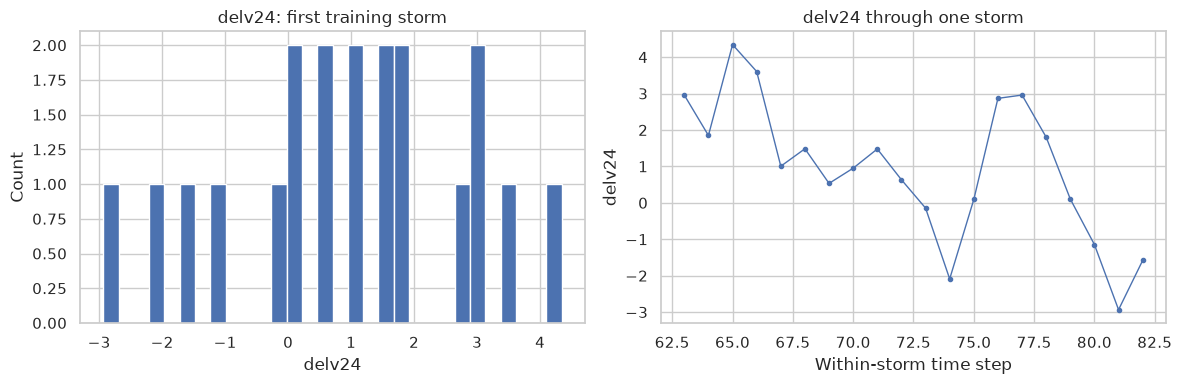

A single storm is not necessarily representative of the whole dataset; try a few others by changing first_key above.


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

first_storm[target_name].dropna().hist(bins=30, ax=axes[0])
axes[0].set_title(f'{target_name}: first training storm')
axes[0].set_xlabel(target_name)
axes[0].set_ylabel('Count')

axes[1].plot(first_storm[target_name].to_numpy(), marker='.', linewidth=1)
axes[1].set_title(f'{target_name} through one storm')
axes[1].set_xlabel('Within-storm time step')
axes[1].set_ylabel(target_name)

plt.tight_layout()
plt.show()

print('A single storm is not necessarily representative of the whole dataset; '
      'try a few others by changing first_key above.')

### Q2.1 — Exploring Causal Settings and Link Assumptions

Causal discovery depends not only on the data and statistical thresholds but also on our assumptions about possible relationships between variables.

**SHIPS** (Statistical Hurricane Intensity Prediction Scheme) is the operational statistical model for intensity forecasting (DeMaria and Kaplan, 1994; reference 5 below). Its predictors occupy the first entries of `var_names` — `ships_ind=23` in `link_shipsera5` — and the ERA5 fields follow.

In the paper, we investigate different configurations for selecting tropical cyclone intensity predictors. These include retaining existing SHIPS predictors while searching for additional ERA5-based predictors, and allowing the algorithm to examine the available predictors more freely.

In this tutorial, we explore three configurations defined in the `causal_settings` module:

1. **SHIPS-only, without additional ERA5 predictors:** Uses the SHIPS variables to identify candidate predictors of intensity change, without adding the broader ERA5 predictor set.
2. **SHIPS + ERA5, with link assumptions:** Prescribes existing SHIPS links while allowing additional ERA5 predictors to be investigated.
3. **SHIPS + ERA5, without link assumptions:** Allows the algorithm to evaluate the available predictors without prescribing the same SHIPS links.

#### Understanding Link Assumptions in Tigramite

Tigramite allows us to incorporate prior knowledge about possible causal relationships through `link_assumptions`. The symbols specify which links are prescribed and which remain candidates for discovery:

- **`-->` — Assumed link:** The link is specified as existing in the assumed direction. M-PC does not test whether to remove it.
- **`-?>` — Possible link:** The link may or may not exist, but its direction is specified if it does. M-PC uses conditional independence tests to assess candidate links during the discovery process.
- **Link not specified:** When an explicit `link_assumptions` dictionary is provided, omitted links are assumed absent.

In our SHIPS + ERA5 configuration with link assumptions, existing SHIPS links are retained while additional ERA5 predictors are investigated as possible links. Without these assumptions, the algorithm has greater freedom to select or exclude available predictors.

In [11]:
import inspect

print('Available link-assumption builders:')
print([n for n in dir(causal_settings) if n.startswith('link_')])

print('\n--- link_shipsera5 (the one we use) ---')
print(inspect.getsource(causal_settings.link_shipsera5))

Available link-assumption builders:
['link_onlyships', 'link_shipsera5', 'link_shipsera5_withassum']

--- link_shipsera5 (the one we use) ---
def link_shipsera5(numvar=None,lag=None,target_ind=None,ships_ind=23):
    # Creating the causal arrows towards the target
    ships_index = np.arange(0,ships_ind)
    super_dict = collections.defaultdict(list)
    for d in [{(obj,-lag):"-?>"} for obj in ships_index]:
        for k, v in d.items():
            super_dict[k].append(str(v))
    tdict = dict(super_dict)
    
    # Assign causal settings to each target
    result = {key:str(value[0]) for key,value in tdict.items()}
    ships_links= {obj:result for obj in target_ind}
    for vartargetindex in target_ind:
        ships_links[vartargetindex].update({(var, -lagz): '-?>' for var in list(np.arange(0,numvar)) for lagz in range(lag,lag+1)})
        
    empty_list = {}
    for vartargetindex in range(target_ind[-1]+1,numvar):
        empty_list[vartargetindex] = {}
    all_links = ships_link

**Your task:** call `link_shipsera5` twice, for `lag=2` and `lag=4`, then compare how many candidate links each one allows into the target.

💡 **Hints**
- `numvar` is the total number of variables — the target *plus* the predictors, so `len(var_names)`.
- The target sits at index `0`, and the argument expects a list: `target_ind=[0]`.

Before running a new experiment, ensure that the variable indices, target index, and lag settings match the prepared dataset.

In [12]:
numvar = len(var_names)

links_lag2 = causal_settings.link_shipsera5(numvar=numvar, lag=2, target_ind=[0])
links_lag4 = causal_settings.link_shipsera5(numvar=numvar, lag=4, target_ind=[0])

print('Variables supplied:', numvar)
for name, links in [('lag=2', links_lag2), ('lag=4', links_lag4)]:
    into_target = links[0]
    lags_used = sorted({lag for (_, lag) in into_target})
    print(f'{name}: {len(into_target)} candidate links into the target, '
          f'at lag(s) {lags_used}')

Variables supplied: 215
lag=2: 215 candidate links into the target, at lag(s) [-2]
lag=4: 215 candidate links into the target, at lag(s) [-4]


### Interpretation

The function takes the number of variables, the lag, and the target index, then returns the link-assumption structure expected by the custom M-PC pipeline.

In the supplied implementation, `link_shipsera5` constructs candidate links at exactly `-lag`, using `range(lag, lag + 1)`. It therefore specifies a **single lag**, rather than a range of lags. For example, `lag=2` and `lag=4` define different single-lag experiments.

To match these assumptions, set `tau_min0=tau_max0=lag` in the main M-PC run. PC-Stable does not inherently require equal minimum and maximum lag bounds; this setting matches the single-lag configuration used in this tutorial.

**Go further:** Try another causal-setting function and inspect its returned link assumptions. Consider how changing the configuration alters the relationships M-PC can investigate.

**Key point:** Link assumptions define the search space for causal discovery. Prescribing a link is not the same as discovering it from the data, and allowing a link as a candidate does not guarantee that M-PC will retain it. Remember that causal discovery identifies candidate relationships under the chosen assumptions and statistical tests. Predictive correlation alone does not establish causal direction.

### Q2.2 — Run one diagnostic model before the full sweep

A full sweep evaluates many `pc_alpha` values and can take time. `pc_alpha` is the significance level of the conditional-independence tests: lower values are stricter and retain fewer parents, higher values admit more. Part IV examines this trade-off in detail.

First run **one** configuration and inspect the selected parents of the target. Then, if runtime permits, change one setting at a time (for example `pilot_alpha` or `pilot_lag`) and compare the result.

**Questions**
1. What changes when `pc_alpha` changes? What stays fixed in this diagnostic run?
2. Does the target's selected parent set change when you alter the significance threshold or lag assumptions?
3. Why should a change in the discovered graph be reported even if it does not improve downstream forecast skill?
4. Why is this pilot not a replacement for the systematic sweep?

First we convert the storms into the plain NumPy arrays the pipeline expects. `train_PC1.Pipeline` hard-codes `missing_flag=-999.0` when it builds the Tigramite `DataFrame`, so the sentinel written here must match: a value such as `999.0` would be treated as a real observation.

In [13]:
MISSING_FLAG = -999.0

Xnorml_c = {}
for part in ('train', 'valid', 'test'):
    Xnorml_c[part] = {}
    for i, key in enumerate(Xnorml[part]):
        arr = np.asarray(Xnorml[part][key], dtype=float).copy()
        arr[~np.isfinite(arr)] = MISSING_FLAG
        Xnorml_c[part][i] = arr


def fresh_storm_dict(part):
    """Tigramite mutates the arrays it is given, so hand every run its own copies."""
    return {key: arr.copy() for key, arr in Xnorml_c[part].items()}


print('Prepared storm counts:', {p: len(s) for p, s in Xnorml_c.items()})
print('Example training array shape:', next(iter(Xnorml_c['train'].values())).shape)
for part, storms in Xnorml_c.items():
    nonfinite = sum((~np.isfinite(a)).sum() for a in storms.values())
    sentinels = sum((a == MISSING_FLAG).sum() for a in storms.values())
    print(f'  {part:6s}: non-finite remaining={nonfinite}, sentinel values={sentinels}')
    assert nonfinite == 0, f'Non-finite values remain in {part}.'

Prepared storm counts: {'train': 184, 'valid': 31, 'test': 31}
Example training array shape: (83, 215)
  train : non-finite remaining=0, sentinel values=2371665
  valid : non-finite remaining=0, sentinel values=244670
  test  : non-finite remaining=0, sentinel values=211345


**Your task:** complete the pilot run below. The link assumptions permit links at one lag only, so both Tigramite lag bounds must equal `pilot_lag`.

💡 **Hint:** the arguments are `pc_alpha=`, `tau_min0=` and `tau_max0=`.

**Note:** This cell runs M-PC once and takes roughly 5-30 seconds. Change only one setting per comparison and record the setting used.

In [14]:
pilot_alpha = 0.05
pilot_lag = 2    # try 4 as well; link_shipsera5 permits links at this lag only

pilot_links = causal_settings.link_shipsera5(
    numvar=len(var_names), lag=pilot_lag, target_ind=[0]
)

pilot_pipeline = train_PC1.Pipeline(
    data=fresh_storm_dict('train'),
    pc_alpha=pilot_alpha,  # the significance threshold defined just above
    pc_type='run_pcstable',
    tau_min0=pilot_lag,    # match the single lag permitted by pilot_links
    tau_max0=pilot_lag,
    var_name=var_names,
    cond_ind_test=ParCorr(significance='analytic'),
    link_assumptions=pilot_links,
)
pilot_result = pilot_pipeline.run_tigramite()

print('Pilot alpha:', pilot_alpha, '| tested lag:', pilot_lag)
print('Target-parent entries:', pilot_result.get(0, []))

Pilot alpha: 0.05 | tested lag: 2
Target-parent entries: [(np.int64(0), -2), (np.int64(17), -2), (np.int64(2), -2), (np.int64(123), -2), (np.int64(145), -2), (np.int64(144), -2), (np.int64(16), -2), (np.int64(155), -2), (np.int64(148), -2)]


In [15]:
# Map the selected target parents to variable names
target_parents = pilot_result.get(0, [])

print(f'Target: {var_names[0]}')
print(f'Pilot alpha: {pilot_alpha} | Pilot lag: {pilot_lag}')
print('\nSelected target parents:')
print('-' * 75)
for var_idx, lag_val in target_parents:
    var_idx = int(var_idx)
    print(f'Variable index: {var_idx:3d} | '
          f'Variable name: {var_names[var_idx]:30s} | '
          f'Lag: {lag_val}')

Target: delv24
Pilot alpha: 0.05 | Pilot lag: 2

Selected target parents:
---------------------------------------------------------------------------
Variable index:   0 | Variable name: delv24                         | Lag: -2
Variable index:  17 | Variable name: sdir                           | Lag: -2
Variable index:   2 | Variable name: wind10                         | Lag: -2
Variable index: 123 | Variable name: outrhum_1000                   | Lag: -2
Variable index: 145 | Variable name: shear_1000_700                 | Lag: -2
Variable index: 144 | Variable name: shear_1000_500                 | Lag: -2
Variable index:  16 | Variable name: tadv                           | Lag: -2
Variable index: 155 | Variable name: shear_850_250.1                | Lag: -2
Variable index: 148 | Variable name: shear_850_300                  | Lag: -2


### Question: Which predictors does M-PC identify as potential causes of the target for this pilot run?
1. How many distinct predictors are selected?
2. What does the lag value of −2 mean when the data are sampled every six hours?
3. Why might changing `pilot_alpha` or `pilot_lag` change the selected predictors?
4. Does a variable selected by M-PC necessarily improve intensity-forecast performance?

Important interpretation: A lag of −2 represents a variable two time steps in the past—12 hours earlier for six-hourly data. The selected links indicate conditional dependencies under the specified causal-discovery assumptions; they should not automatically be interpreted as proof of physical causation.

### M-PC significance alpha sweep

After attempting the exploration above, run this section to reproduce the main configuration. The main sweep restores `lag = 4` following the paper as the target is DELV24. It reuses the prepared storm dictionaries instead of rebuilding them inside every iteration. The validation/test partitions are retained for the evaluation sections, while M-PC discovery itself uses the training storms.

The sweep takes roughly **5-10 minutes**, growing slower as `pc_alpha` increases, because looser thresholds retain more parents. A precomputed result for fold 3 ships with this module and is loaded by default, so you can continue to Part IV without waiting. Set `RUN_FULL_SWEEP = True` to compute it yourself — and you must do so if you changed `FOLD`.

In [16]:
RUN_FULL_SWEEP = False   # set True to recompute the sweep (~5-10 min)

lag = 4
pc_alpha_grid = [
    0.001, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09,
    0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9,
]

print(f'Fold {FOLD}; target={target_name}; tested lag={lag}; '
      f'{len(pc_alpha_grid)} alpha settings')

Fold 3; target=delv24; tested lag=4; 19 alpha settings


In [17]:
CACHE_URL = "https://raw.githubusercontent.com/ecmwf-training/2026-ml-esm-training/main/c3/m9/_resources/mpc_sweep_fold{FOLD}.json"
cache_file = f"mpc_sweep_fold{FOLD}.json"

if RUN_FULL_SWEEP:
    sweep_links = causal_settings.link_shipsera5(
        numvar=len(var_names), lag=lag, target_ind=[0]
    )
    results = []
    for pc_alpha in tqdm(pc_alpha_grid, desc=f'M-PC sweep (fold {FOLD})'):
        run = train_PC1.Pipeline(
            data=fresh_storm_dict('train'),
            pc_alpha=pc_alpha,
            pc_type='run_pcstable',
            tau_min0=lag,
            tau_max0=lag,
            var_name=var_names,
            cond_ind_test=ParCorr(significance='analytic'),
            link_assumptions=sweep_links,
        )
        results.append(run.run_tigramite())
        gc.collect()
    # Keep only what the downstream analysis needs: the target's parents per alpha.
    target_parents_by_alpha = [
        [[int(i), int(l)] for i, l in r.get(0, [])] for r in results
    ]
    with open(cache_file, 'w') as f:
        json.dump({'fold': FOLD, 'lag': lag, 'pc_alpha_grid': pc_alpha_grid,
                   'target_parents': target_parents_by_alpha,
                   'var_names': var_names}, f)
    print(f'Completed {len(results)} M-PC runs; cached to {cache_file}')
else:
    if not os.path.exists(cache_file):
        print('Downloading the precomputed M-PC sweep ...')
        urllib.request.urlretrieve(CACHE_URL.format(FOLD=FOLD), cache_file)
    with open(cache_file) as f:
        cached = json.load(f)
    assert cached['fold'] == FOLD, (
        f"Cached sweep is for fold {cached['fold']}, but FOLD={FOLD}. "
        'Set RUN_FULL_SWEEP = True to compute this fold.'
    )
    assert cached['var_names'] == var_names, (
        'Cached variable names do not match the loaded data.'
    )
    lag = cached['lag']
    pc_alpha_grid = cached['pc_alpha_grid']
    target_parents_by_alpha = cached['target_parents']
    print(f'Loaded precomputed sweep: {len(pc_alpha_grid)} alpha settings, lag={lag}')

print('Parents found per alpha:',
      {a: len(p) for a, p in zip(pc_alpha_grid, target_parents_by_alpha)})

Loaded precomputed sweep: 19 alpha settings, lag=4
Parents found per alpha: {0.001: 5, 0.01: 7, 0.02: 8, 0.03: 8, 0.04: 10, 0.05: 11, 0.06: 11, 0.07: 11, 0.08: 11, 0.09: 12, 0.1: 13, 0.2: 14, 0.3: 15, 0.4: 18, 0.5: 19, 0.6: 23, 0.7: 30, 0.8: 39, 0.9: 54}


---

## Part IV. Evaluating causal subsets and model parsimony

Once the Multi-dataset Peter–Clark (M-PC) algorithm has mapped the conditional independence structure across our significance grid ($\alpha$), we must determine which subset of discovered drivers yields the most robust out-of-sample forecast.

### The Significance Sweep & Parsimony Trade-off
* **The Role of $\alpha$:** The significance threshold ($pc_\alpha$) controls how stringent the conditional independence tests are. Stricter (lower) $\alpha$ values yield sparser graphs with fewer predictors, while looser values admit more potential drivers.
* **Downstream Multiple Linear Regression (MLR):** To evaluate the predictive utility of the discovered causal parents, we train an ordinary least squares Multiple Linear Regression model on each alpha configuration's selected subset.
* **Selecting the Optimal Model:** By evaluating performance across a validation split, we identify the peak configuration that avoids both underfitting (missing critical physical drivers) and overfitting (retaining noisy, multicollinear covariates).

In the code block below, we load the saved sweep results, map Tigramite's absolute variable indices back to our predictor array, and extract the peak performing feature subset for downstream verification.

### Q3.1 — Inspect what M-PC selected before fitting a forecast model

Inspect the target's discovered parents for a few alpha values. The stored parent tuples contain a variable index and lag. Tigramite's variable index 0 is the target, whereas `X_tr` contains predictors only; therefore, map a discovered predictor index back to the predictor array by subtracting one.

**Explore:** Do stricter and looser significance thresholds produce the same number or identity of candidate parents? Are lagged copies of the same variable counted once in the downstream predictor subset?

In [18]:
# Inspect the discovered parents at a strict, a middle and a loose threshold.
for idx in sorted({0, len(pc_alpha_grid) // 2, len(pc_alpha_grid) - 1}):
    parents = target_parents_by_alpha[idx]
    names = [var_names[i] for i, _ in parents]
    print(f'pc_alpha={pc_alpha_grid[idx]:<6} -> {len(parents):2d} parents: '
          f'{names[:8]}{" ..." if len(names) > 8 else ""}')

pc_alpha=0.001  ->  5 parents: ['wind10', 'sdir', 'shear_1000_850.1', 'outrhum_1000', 'shear_1000_500']
pc_alpha=0.09   -> 12 parents: ['wind10', 'sdir', 'shear_1000_850.1', 'outrhum_1000', 'outrhum_850', 'shear_850_300', 'tgrad_200_800', 'tadv'] ...
pc_alpha=0.9    -> 54 parents: ['wind10', 'shear_1000_850.1', 'sdir', 'shear_850_300', 'tadv', 'vort_700', 'outrhum_1000', 'div_0_1000_150'] ...


**Your task:** complete the index conversion and the guard condition below.

💡 **Hints**
- Convert the Tigramite index `pred_idx` into the corresponding `X_tr` column.
- Skip the entry when `pred_idx` refers to the target itself, which is the target's own past (autocorrelation) and is not a column of `X_tr`.
- The same variable can appear at several lags; it should be counted once.

The sanity check beneath the function prints the names Tigramite reported next to the names recovered from `X_tr`. An off-by-one error here would shift every predictor name while still looking plausible.

In [19]:
def parents_to_columns(parents):
    """Convert Tigramite target-parent entries into X_tr column indices."""
    selected = []
    for pred_idx, lag_val in parents:
        pred_idx = int(pred_idx)
        feat_idx = pred_idx - 1             # Tigramite index -> X_tr column
        if pred_idx != 0 and 0 <= feat_idx < len(feature_names) \
                and feat_idx not in selected:
            selected.append(feat_idx)
    return selected


# Sanity check: the names we recover must match the names Tigramite reported.
_probe = target_parents_by_alpha[0]
print('Tigramite says:', [var_names[i] for i, _ in _probe if i != 0])
print('We recover:   ', [feature_names[i] for i in parents_to_columns(_probe)])

Tigramite says: ['wind10', 'sdir', 'shear_1000_850.1', 'outrhum_1000', 'shear_1000_500']
We recover:    ['wind10', 'sdir', 'shear_1000_850.1', 'outrhum_1000', 'shear_1000_500']


**Evaluate every alpha using the same downstream MLR protocol**

This evaluation uses the validation score to choose the preferred configuration. The test score is retained for final reporting and should not be used to select `pc_alpha`. If no target parents are found, the existing workflow uses predictor index 0 as a fallback; treat that fallback as a modelling safeguard, not as a discovered causal parent.

In [20]:
records = []
for pc_alpha, parents in zip(tqdm(pc_alpha_grid, desc='MLR on causal subsets'),
                             target_parents_by_alpha):
    cols = parents_to_columns(parents)

    if cols:
        mlr = LinearRegression().fit(X_tr[:, cols], y_tr)
        tr_pred = mlr.predict(X_tr[:, cols])
        val_pred = mlr.predict(X_val[:, cols])
        te_pred = mlr.predict(X_te[:, cols])
        selected = [feature_names[i] for i in cols]
    else:
        # Fallback used by the original workflow: predictor index 0.
        cols = [0]
        mlr = LinearRegression().fit(X_tr[:, cols], y_tr)
        tr_pred = mlr.predict(X_tr[:, cols])
        val_pred = mlr.predict(X_val[:, cols])
        te_pred = mlr.predict(X_te[:, cols])
        selected = [feature_names[0]]

    records.append({
        'pc_alpha': pc_alpha,
        'num_vars': len(cols),
        'selected_indices': cols,
        'selected_features': selected,
        'train_r2': r2_score(y_tr, tr_pred),
        'val_r2': r2_score(y_val, val_pred),
        'test_r2': r2_score(y_te, te_pred),
        'model': mlr,
    })

causal_eval_df = pd.DataFrame(records)
display(causal_eval_df[['pc_alpha', 'num_vars', 'train_r2', 'val_r2', 'test_r2']])

MLR on causal subsets:   0%|          | 0/19 [00:00<?, ?it/s]

,pc_alpha,num_vars,train_r2,val_r2,test_r2
0,0.001,5,0.148156,0.118778,0.147925
1,0.010,7,0.170736,0.146886,0.177659
2,0.020,8,0.150932,0.126791,0.159249
3,0.030,8,0.150932,0.126791,0.159249
4,0.040,10,0.191618,0.183857,0.204895
5,0.050,11,0.200209,0.181403,0.212624
6,0.060,11,0.193025,0.183800,0.211540
7,0.070,11,0.197686,0.183341,0.218727
8,0.080,11,0.197686,0.183341,0.218727
9,0.090,12,0.206923,0.195186,0.225771


Notice that several nearby `pc_alpha` values produce identical results, so testing many closely spaced values may not always be worthwhile. The selected predictors and forecasting performance also depend on the chosen time lag; for example, using `lag=1` instead of `lag=4` could yield a different set of results.

In [21]:
peak_row = causal_eval_df.loc[causal_eval_df['val_r2'].idxmax()]

causal_res = {
    'Method': 'Causal M-PC + MLR',
    'Predictors': int(peak_row['num_vars']),
    'Train R2': peak_row['train_r2'],
    'Validation R2': peak_row['val_r2'],
    'Test R2 (Unseen)': peak_row['test_r2'],
    'Selected Features': peak_row['selected_features'],
    'Indices': peak_row['selected_indices'],
    'Model': peak_row['model'],
}

print(f'PEAK CAUSAL MLR CONFIGURATION - fold {FOLD}')
print(f"  pc_alpha:            {peak_row['pc_alpha']}")
print(f"  selected predictors: {peak_row['num_vars']}")
print(f"  train R2:            {peak_row['train_r2']:.4f}")
print(f"  validation R2:       {peak_row['val_r2']:.4f}")
print(f"  test R2 (unseen):    {peak_row['test_r2']:.4f}")
print('\nSelected features:')
for j, feat in enumerate(peak_row['selected_features'], 1):
    print(f'  {j:2d}. {feat}')

PEAK CAUSAL MLR CONFIGURATION - fold 3
  pc_alpha:            0.8
  selected predictors: 38
  train R2:            0.3298
  validation R2:       0.2924
  test R2 (unseen):    0.3212

Selected features:
   1. wind10
   2. shear_1000_850.1
   3. outrhum_1000
   4. sdir
   5. shear_850_300
   6. tadv
   7. vort_700
   8. div_0_1000_150
   9. outtemp_150
  10. z850
  11. pwat_400_600
  12. div_100
  13. pvor_1000
  14. tgrad_0_500
  15. outdiv_850
  16. div_0_1000_250
  17. pvor_850
  18. VPER
  19. div_300
  20. gpot_850
  21. div_1000
  22. pvor_500
  23. vort_1000
  24. outtemp_100
  25. rhum_400
  26. shear_1000_200
  27. outrhum_850
  28. outeqt700
  29. outrhum_250
  30. shear_1000_700
  31. outtemp_500
  32. temp_100
  33. gpot_800
  34. pvor_700
  35. vort_0_1000_200
  36. outvort_200
  37. outdiv_1000
  38. tanom300


### Q3.2 — Interpret the selected causal subset

The evaluation cells above fit downstream MLR models for each discovered subset and choose the configuration with the highest validation $R^2$.

1. Which `pc_alpha` value is selected?
2. How many predictors are retained?
3. Why should the validation score—not the test score—determine this choice?

**Hint:** Inspect `peak_row` and `causal_eval_df`. A lower predictor count is not automatically better; parsimony must be considered alongside validation performance.

Coding help: [scikit-learn linear regression](https://scikit-learn.org/stable/modules/linear_model.html) and [R² score](https://scikit-learn.org/stable/modules/model_evaluation.html#r2-score).

## Part V. Benchmark against conventional feature selection

The causal subset must be compared with alternatives using the **same training, validation, and unseen-test partitions**. Here we compare (1) absolute Pearson-correlation ranking + MLR, (2) Random Forest importance ranking + MLR, and (3) an MLR using all candidate predictors. These are predictive baselines; neither correlation nor Random Forest importance is a causal-discovery method.

### Q4.1 — How do simple correlation rankings look?

Explore the distribution of feature–target correlations. Which predictors rank highly by absolute correlation? Why does a strong marginal correlation not, by itself, establish a direct causal relationship?

**Your task:** compute each predictor's Pearson correlation with the target, using training data only.

💡 **Hint:** `np.corrcoef(a, b)` returns a 2×2 matrix; the correlation you want is at `[0, 1]`.

In [22]:
corr_with_y = np.array([
    np.corrcoef(X_tr[:, i], y_tr)[0, 1] for i in range(X_tr.shape[1])
])
corr_with_y = np.nan_to_num(corr_with_y, nan=0.0)
corr_ranked = np.argsort(np.abs(corr_with_y))[::-1]

corr_rank_table = pd.DataFrame({
    'Feature': [feature_names[i] for i in corr_ranked],
    'Pearson r': corr_with_y[corr_ranked],
    'Absolute r': np.abs(corr_with_y[corr_ranked]),
})
display(corr_rank_table.head(15))

,Feature,Pearson r,Absolute r
0,shear_1000_850,-0.345239,0.345239
1,shear_1000_700,-0.320659,0.320659
2,pvor_700,-0.317751,0.317751
3,pvor_850,-0.306370,0.306370
4,shear_1000_500,-0.298465,0.298465
5,shear_1000_850.1,-0.294123,0.294123
6,pvor_1000,-0.293173,0.293173
7,POT2,0.287646,0.287646
8,wind10,-0.274523,0.274523
9,POT,0.266970,0.266970


### Q4.2 — How does Random Forest rank the same predictor pool?

Fit the Random Forest using training data only, then inspect its feature-importance ranking. Compare its top features with the correlation ranking. Why might the rankings differ? What limitation does impurity-based feature importance have when predictors are correlated?

**Your task:** fit the Random Forest and rank its feature importances.

💡 **Hint:** use `n_estimators=50`, `random_state=42` for reproducibility, and `n_jobs=-1` to use all cores.

In [23]:
rf = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
rf.fit(X_tr, y_tr)

rf_ranked = np.argsort(rf.feature_importances_)[::-1]
rf_rank_table = pd.DataFrame({
    'Feature': [feature_names[i] for i in rf_ranked],
    'RF importance': rf.feature_importances_[rf_ranked],
})
display(rf_rank_table.head(15))

,Feature,RF importance
0,shear_1000_850,0.081133
1,wind10,0.052142
2,pvor_850,0.027977
3,pvor_700,0.022539
4,pwat_0_200,0.017113
5,rhum_200,0.014146
6,outsst,0.014046
7,vort_1000,0.014035
8,rh_0_500_200,0.011954
9,sdir,0.010937


### Q4.3 — What does the feature-count sweep test?

Each ranking is evaluated with increasingly large top-*k* subsets. The number of selected features is chosen using validation R². Before running the sweep, predict what may happen as *k* grows: must validation performance improve monotonically? Why is it important to use the same maximum feature count for both rankings?

**Your task:** complete the fit and the validation score inside the loop.

💡 **Hint:** `sub` holds the column indices for this value of *k*, so the design matrix is `X_tr[:, sub]`.

In [24]:
def sweep_baseline(rank_order, label, max_features=30):
    best_v, best_k, best_tr, best_te, best_m = -np.inf, 1, 0.0, 0.0, None
    k_range = range(1, min(max_features + 1, len(rank_order) + 1))
    pbar = tqdm(k_range, desc=f'Sweeping {label}', leave=False, unit='model_size')

    for k in pbar:
        sub = rank_order[:k]
        model = LinearRegression().fit(X_tr[:, sub], y_tr)
        val_r2 = r2_score(y_val, model.predict(X_val[:, sub]))
        if val_r2 > best_v:
            best_v, best_k, best_m = val_r2, k, model
            best_tr = r2_score(y_tr, model.predict(X_tr[:, sub]))
            best_te = r2_score(y_te, model.predict(X_te[:, sub]))
        pbar.set_postfix({'Best K': best_k, 'Best Val R²': f'{best_v:.3f}'})

    return {
        'Method': label, 'Predictors': best_k, 'Train R2': best_tr,
        'Validation R2': best_v, 'Test R2 (Unseen)': best_te,
        'Selected Features': [feature_names[i] for i in rank_order[:best_k]],
        'Indices': list(rank_order[:best_k]), 'Model': best_m,
    }


corr_best = sweep_baseline(corr_ranked, 'Correlation FS + MLR')
rf_best = sweep_baseline(rf_ranked, 'Random Forest FS + MLR')

print('Correlation best K:', corr_best['Predictors'],
      '| validation R²:', round(corr_best['Validation R2'], 4))
print('Random Forest best K:', rf_best['Predictors'],
      '| validation R²:', round(rf_best['Validation R2'], 4))

Sweeping Correlation FS + MLR:   0%|          | 0/30 [00:00<?, ?model_size/s]

Sweeping Random Forest FS + MLR:   0%|          | 0/30 [00:00<?, ?model_size/s]

Correlation best K: 28 | validation R²: 0.2658
Random Forest best K: 30 | validation R²: 0.2724


### Q4.4 — What is the cost of retaining every predictor?

Fit the full-feature MLR as a reference. Compare its train, validation, and test scores with the feature-selected models. Does a higher training score carry over to held-out storms? Discuss model complexity and correlated predictors, without assuming that a smaller subset must always perform better.

In [25]:
m_all = LinearRegression().fit(X_tr, y_tr)

all_res = {
    'Method': f'All {len(feature_names)} Features (No FS)',
    'Predictors': len(feature_names),
    'Train R2': r2_score(y_tr, m_all.predict(X_tr)),
    'Validation R2': r2_score(y_val, m_all.predict(X_val)),
    'Test R2 (Unseen)': r2_score(y_te, m_all.predict(X_te)),
    'Selected Features': f'All {len(feature_names)} predictors',
    'Indices': list(range(len(feature_names))),
    'Model': m_all,
}

summary_table = pd.DataFrame([causal_res, corr_best, rf_best, all_res])
print('BENCHMARK COMPARISON — unseen test storms')
display(summary_table[['Method', 'Predictors', 'Train R2',
                       'Validation R2', 'Test R2 (Unseen)']])

BENCHMARK COMPARISON — unseen test storms


,Method,Predictors,Train R2,Validation R2,Test R2 (Unseen)
0,Causal M-PC + MLR,38,0.329782,0.292435,0.321177
1,Correlation FS + MLR,28,0.244790,0.265793,0.207117
2,Random Forest FS + MLR,30,0.298428,0.272435,0.297324
3,All 214 Features (No FS),214,0.455840,0.347666,0.008257


**Interpretation guide for Q4**

Use your actual table to answer the questions; the winning method can vary by fold. Note in particular any method whose validation and unseen-test scores disagree sharply, since the validation storms were used to choose the configuration.

Select configurations using validation data, and treat test metrics as final held-out estimates. This is one selected fold, so it does not establish performance across all folds or prove that the selected predictors are causal. A causal-discovery method and a predictive ranking method answer different questions.

## Part VI. Test whether a nonlinear predictor changes the result

The M-PC feature subset can be passed to different forecasting models. Here, an MLP tests whether a nonlinear mapping improves prediction relative to the causal-subset MLR. This is a model comparison, not a second causal-discovery step.

### Q5.1 — Fit an MLP on the same causal subset

Inspect `hidden_layer_sizes`, `alpha`, `max_iter`, and `early_stopping`. Before training, write down one controlled experiment: change **one** setting and predict how it might affect fit, generalization, and runtime. Keep the selected causal predictors and data splits fixed so the comparison remains interpretable. If you experiment with hyperparameters, record each configuration and avoid repeatedly tuning against the test score.

Neural networks are sensitive to input scale, so the predictors and the target are standardised using statistics from the training set only; fitting the scaler on validation or test data would leak information about the held-out storms.

**Your task:** complete the scaling, the fit, and the inverse transform. Because the model is trained on a standardised target, its raw predictions are in standardised units and must be mapped back before scoring against `y_tr`, `y_val` and `y_te`.

💡 **Hints**
- `fit_transform` on training data; plain `transform` on validation and test.
- `scaler_y.inverse_transform(pred.reshape(-1, 1)).ravel()` undoes the target scaling.

In [26]:
cols = peak_row['selected_indices']
X_tr_causal, X_val_causal, X_te_causal = X_tr[:, cols], X_val[:, cols], X_te[:, cols]

# Standardise the predictors using TRAINING statistics only
scaler_X = StandardScaler()
X_tr_scaled = scaler_X.fit_transform(X_tr_causal)
X_val_scaled = scaler_X.transform(X_val_causal)
X_te_scaled = scaler_X.transform(X_te_causal)

# Standardise the target the same way
scaler_y = StandardScaler()
y_tr_scaled = scaler_y.fit_transform(np.asarray(y_tr).reshape(-1, 1)).ravel()

mlp = MLPRegressor(
    hidden_layer_sizes=(512, 512, 512, 512),
    activation='relu',
    solver='adam',
    learning_rate_init=0.001,
    max_iter=1000,
    random_state=42,
    early_stopping=False,
)
mlp.fit(X_tr_scaled, y_tr_scaled)

# Predictions come out standardised - map them back to physical units
def unscale(pred):
    return scaler_y.inverse_transform(pred.reshape(-1, 1)).ravel()

y_tr_pred = unscale(mlp.predict(X_tr_scaled))
y_val_pred = unscale(mlp.predict(X_val_scaled))
y_te_pred = unscale(mlp.predict(X_te_scaled))

print('MLP fitted. Iterations used:', mlp.n_iter_)

MLP fitted. Iterations used: 46


In [27]:
# Evaluate on all three partitions
mlp_tr_r2 = r2_score(y_tr, y_tr_pred)
mlp_val_r2 = r2_score(y_val, y_val_pred)
mlp_te_r2 = r2_score(y_te, y_te_pred)

print(f'Train R²: {mlp_tr_r2:.4f}')
print(f'Validation R²: {mlp_val_r2:.4f}')
print(f'Test R² (unseen storms): {mlp_te_r2:.4f}')
print(f'\nTrain - validation gap: {mlp_tr_r2 - mlp_val_r2:.4f}')

Train R²: 0.9854
Validation R²: 0.2457
Test R² (unseen storms): 0.3528

Train - validation gap: 0.7397


### Q5.2 — Does the nonlinear model change the conclusion?

Compare the MLP with causal MLR and the baseline methods. Does MLP improve validation performance? Does that improvement carry over to unseen storms? Is the train–validation gap consistent with overfitting? Why would better MLP performance still not prove that the selected features are causal?

In [28]:
mlp_res = {
    'Method': 'Causal M-PC + MLP',
    'Predictors': int(peak_row['num_vars']),
    'Train R2': mlp_tr_r2,
    'Validation R2': mlp_val_r2,
    'Test R2 (Unseen)': mlp_te_r2,
    'Selected Features': peak_row['selected_features'],
    'Indices': peak_row['selected_indices'],
    'Model': mlp,
}

summary_with_mlp = pd.DataFrame([causal_res, mlp_res, corr_best, rf_best, all_res])
display(
    summary_with_mlp[['Method', 'Predictors', 'Train R2',
                      'Validation R2', 'Test R2 (Unseen)']]
    .sort_values('Validation R2', ascending=False)
    .reset_index(drop=True)
)

mlr_row = summary_with_mlp[summary_with_mlp['Method'] == 'Causal M-PC + MLR'].iloc[0]
print('MLP minus causal MLR validation R²:',
      round(mlp_res['Validation R2'] - mlr_row['Validation R2'], 4))
print('MLP minus causal MLR test R²:',
      round(mlp_res['Test R2 (Unseen)'] - mlr_row['Test R2 (Unseen)'], 4))

,Method,Predictors,Train R2,Validation R2,Test R2 (Unseen)
0,All 214 Features (No FS),214,0.455840,0.347666,0.008257
1,Causal M-PC + MLR,38,0.329782,0.292435,0.321177
2,Random Forest FS + MLR,30,0.298428,0.272435,0.297324
3,Correlation FS + MLR,28,0.244790,0.265793,0.207117
4,Causal M-PC + MLP,38,0.985410,0.245733,0.352849


MLP minus causal MLR validation R²: -0.0467
MLP minus causal MLR test R²: 0.0317


**Interpretation guide for Q5**

A positive validation-score difference means the MLP performed better on this validation split; it does not guarantee better unseen-storm performance. If training performance is much stronger than validation performance, overfitting is one possible explanation. The feature set was selected by M-PC, but the MLP itself optimizes predictive error rather than causal validity.

---

## 🎁 Bonus: Understanding Model Predictions with SHAP

Congratulations on reaching this stage of the tutorial! We have explored how causal discovery can help identify relevant predictors of tropical cyclone intensity change and how these predictors can be incorporated into a forecasting model.

The next question is: **How can we interpret the model's predictions?**

**SHAP (SHapley Additive exPlanations)** provides a framework for attributing individual predictions to their input features. It complements our earlier analysis by helping us understand how the trained model uses the selected predictors.

In this section, we will use SHAP to investigate:

- **Feature importance:** Which predictors contribute most to the model's predictions across the dataset?
- **Feature contributions:** How do different values of a predictor contribute to individual predictions?
- **Meteorological consistency:** Are the attribution patterns consistent with our physical understanding of tropical cyclone intensity change, or do they suggest relationships worth investigating further?

Model interpretation is particularly valuable in weather and climate applications, where predictive performance alone does not tell us whether a model behaves in a physically plausible way.

SHAP explains the behaviour of the fitted model; its attributions do not independently establish causal relationships or physical mechanisms. Combined with causal discovery, however, it offers a complementary perspective on predictor relevance and model behaviour.

### Step 1: Identify the features used by the model

Our MLR model uses the predictors selected by causal discovery. We first retrieve their feature names so that we can interpret the SHAP results in meteorological terms rather than referring to features by their array indices.

In [29]:
# Indices of the predictors selected by causal discovery
causal_indices = peak_row['selected_indices']
causal_feature_names = [feature_names[i] for i in causal_indices]

print(f'Number of causal features: {len(causal_feature_names)}')
print('Selected features:', causal_feature_names)

Number of causal features: 38
Selected features: ['wind10', 'shear_1000_850.1', 'outrhum_1000', 'sdir', 'shear_850_300', 'tadv', 'vort_700', 'div_0_1000_150', 'outtemp_150', 'z850', 'pwat_400_600', 'div_100', 'pvor_1000', 'tgrad_0_500', 'outdiv_850', 'div_0_1000_250', 'pvor_850', 'VPER', 'div_300', 'gpot_850', 'div_1000', 'pvor_500', 'vort_1000', 'outtemp_100', 'rhum_400', 'shear_1000_200', 'outrhum_850', 'outeqt700', 'outrhum_250', 'shear_1000_700', 'outtemp_500', 'temp_100', 'gpot_800', 'pvor_700', 'vort_0_1000_200', 'outvort_200', 'outdiv_1000', 'tanom300']


### Step 2: Set up the SHAP explainer

SHAP compares a model's predictions with a reference prediction, then attributes the difference to individual features. The reference is determined using a background dataset.

Here, we use the training data as the background distribution. We select **interventional SHAP**, which treats the features independently when calculating their contributions rather than explicitly preserving their statistical dependencies.

This is a modelling assumption, not a physical intervention on the atmosphere. Atmospheric variables can be correlated, so the choice of explanation method can affect how contributions are assigned to individual predictors.

In [30]:
import shap

# Use the causal predictors selected by M-PC
X_train_shap = X_tr[:, causal_indices]
X_val_shap = X_val[:, causal_indices]

print('Training data shape:', X_train_shap.shape)
print('Validation data shape:', X_val_shap.shape)

# Use the fitted causal MLR model
mlr_causal_fixed = causal_res['Model']

# Explicitly define the background data for SHAP
background = shap.maskers.Independent(X_train_shap, max_samples=100)
explainer = shap.LinearExplainer(mlr_causal_fixed, background)
print('SHAP explainer initialised.')

Background dataset has 6162 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=6162 when initializing the masker.


Training data shape: (6162, 38)
Validation data shape: (1036, 38)
SHAP explainer initialised.


### Step 3: Calculate the SHAP values and plot them

The beeswarm plot below shows, for each predictor, how its SHAP values are distributed across the validation samples.

SHAP values shape: (1036, 38)


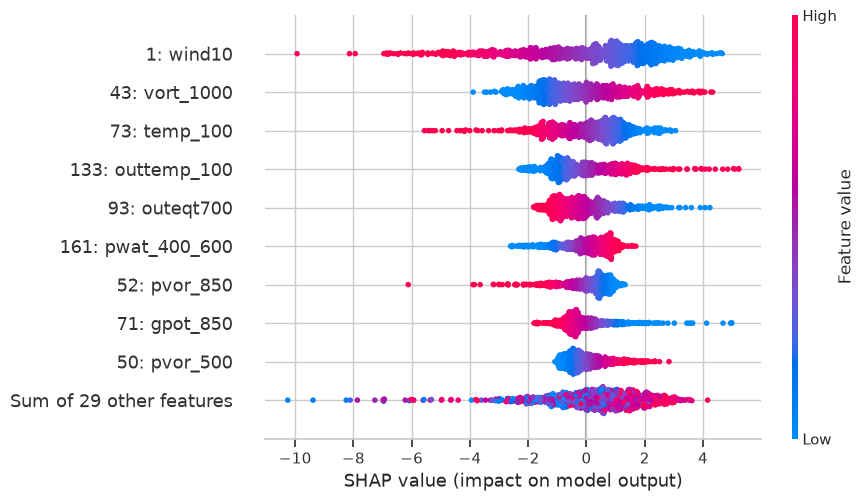

In [31]:
shap_values = explainer(X_val_shap)
print('SHAP values shape:', shap_values.values.shape)

# Combine feature index and variable name for each predictor
feature_labels = [f'{i}: {name}'
                  for i, name in zip(causal_indices, causal_feature_names)]

shap_values_plot = shap.Explanation(
    values=shap_values.values,
    base_values=shap_values.base_values,
    data=X_val_shap,
    feature_names=feature_labels,
)

# Plot the 10 most important features
shap.plots.beeswarm(shap_values_plot, max_display=10)
plt.show()

### Step 4: Interpret the SHAP summary plot

The SHAP summary plot combines feature importance and the distribution of feature contributions across the validation samples.

- **Vertical axis:** Features are ranked by their mean absolute SHAP values, with the most influential features appearing at the top.
- **Horizontal axis:** SHAP value. Positive values increase the model's prediction relative to its reference prediction; negative values decrease it.
- **Point colour:** The original feature value, from low (blue) to high (red).

Look for features with large contributions and examine whether high and low values tend to push predictions in different directions. Compare these patterns with your meteorological understanding, keeping in mind that SHAP explains the fitted model rather than establishing physical causality.

### Q6. What does SHAP tell us—and what does it not tell us?

Use the SHAP summary plot to identify features with large attribution magnitudes and describe how feature values relate to model output in this fitted linear model.

Then explain why SHAP importance is not equivalent to causal importance. SHAP values explain a model's predictions relative to a background distribution; they do not validate the causal-discovery assumptions or establish a physical mechanism.

Coding help: [SHAP documentation](https://shap.readthedocs.io/).

---
## Final Summary and Key Takeaways

You have reached the end of this tutorial! Let's briefly recap the key ideas and methods explored along the way.

- **Causal discovery with M-PC:** Investigated candidate causal relationships across multiple storm time series while preserving their individual temporal structures.

- **Meteorological knowledge and causal constraints:** Incorporated domain knowledge through link assumptions to guide data-driven causal discovery.

- **Causal feature selection for forecasting:** Used selected predictors in a multiple linear regression model and examined whether they contribute to predictive performance.

- **Model evaluation:** Considered the importance of validation and independent storm data when assessing the usefulness of causal feature selection.

- **Model interpretation with SHAP:** Explored how individual features contribute to the fitted model's predictions and how these contributions can be compared with meteorological expectations.

### Final takeaway

Causal discovery, domain knowledge, predictive evaluation, and model interpretation address different questions. Used together, they provide a framework for investigating potential causal relationships and their usefulness for atmospheric forecasting.

Remember that discovered relationships depend on the data and assumptions, SHAP explains the fitted model rather than establishing physical causality, and improved predictive performance must be demonstrated through appropriate evaluation.

Thank you for working through this tutorial!

### Bonus: Reflect on the Evidence and Explore Further

Before finishing, take a moment to connect the different stages of the tutorial.

In **4–6 sentences**, summarise your findings by considering:

1. **Causal discovery:** What does M-PC contribute to identifying candidate predictors of tropical cyclone intensity change?

Ans:

2. **Feature selection:** How does the selected feature subset compare with conventional statistical feature selection methods?

Ans:

3. **Forecasting performance:** Do the validation and unseen-storm results support a predictive benefit from causal feature selection?

Ans:

4. **Limitations:** What is one important limitation of the method or your evaluation?

Ans:

5. **Beyond tropical cyclones:** What other weather or climate applications could benefit from causal feature selection, and why?

Ans:

**Suggested structure:** Discovery method → feature selection comparison → forecasting evidence → limitation → potential applications.

Causal feature selection offers a complementary, physically informed approach to conventional statistical methods. Use the results from your run to assess its predictive value, and consider where this approach might be useful beyond tropical cyclone intensity forecasting—for example, in extreme rainfall prediction, heatwave forecasting, or understanding drivers of climate variability. Remember that the usefulness of a method depends on the scientific question, the available data, and the evidence supporting its results.

### Further coding help

- [NumPy user guide](https://numpy.org/doc/stable/user/)
- [pandas user guide](https://pandas.pydata.org/docs/user_guide/index.html)
- [Matplotlib tutorials](https://matplotlib.org/stable/tutorials/index.html)
- [scikit-learn model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [Tigramite](https://github.com/jakobrunge/tigramite)
- [SHAP](https://shap.readthedocs.io/)

---
## References

1. **Ganesh, S. S., F. I.-H. Tam, M. S. Gomez, M. McGraw, M. DeMaria, K. Musgrave, J. Runge, and T. Beucler**, 2026: *Multidata Causal Discovery for Statistical Hurricane Intensity Forecasting*. **Weather and Forecasting**, 41 (7), 1359–1375, [https://doi.org/10.1175/WAF-D-25-0208.1](https://doi.org/10.1175/WAF-D-25-0208.1).
2. **Ganesh, S. S., et al.**, 2026: *Supplementary Information (SI): Multidata Causal Discovery for Statistical Hurricane Intensity Forecasting*. **Weather and Forecasting**, [https://doi.org/10.1175/WAF-D-25-0208.s1](https://doi.org/10.1175/WAF-D-25-0208.s1).
3. **Ganesh S., S., and F. I.-H. Tam**, 2025: *saranya8989/2025_CausalSHIPS: Causal SHIPS v1.0*. Zenodo, [https://doi.org/10.5281/zenodo.17242382](https://doi.org/10.5281/zenodo.17242382).
4. **Runge, J., P. Nowack, M. Kretschmer, S. Flaxman, and D. Sejdinovic**, 2019: *Detecting and quantifying causal associations in large nonlinear time series datasets*. **Science Advances**, 5 (11), eaau4996, [https://doi.org/10.1126/sciadv.aau4996](https://doi.org/10.1126/sciadv.aau4996).
5. **DeMaria, M., and J. Kaplan**, 1994: *A Statistical Hurricane Intensity Prediction Scheme (SHIPS) for the Atlantic basin*. **Weather and Forecasting**, 9 (2), 209–220, [https://doi.org/10.1175/1520-0434(1994)009<0209:ASHIPS>2.0.CO;2](https://doi.org/10.1175/1520-0434(1994)009%3C0209:ASHIPS%3E2.0.CO;2).
6. **Razin, M. N., C. J. Slocum, J. A. Knaff, P. J. Brown, and M. M. Bell**, 2023: *Tropical Cyclone Precipitation, Infrared, Microwave, and Environmental Dataset (TC PRIMED)*. **Bulletin of the American Meteorological Society**, 104 (11), E1980–E1998, [https://doi.org/10.1175/BAMS-D-21-0052.1](https://doi.org/10.1175/BAMS-D-21-0052.1).